In [1]:
from obspy.core import read, Stream, Trace
from obspy.signal.filter import lowpass,highpass
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from geopy.distance import great_circle, geodesic
import warnings
import glob
import re
from pyproj import CRS, Transformer
import cartopy.crs as ccrs         # to plot maps with different projections
import cartopy.feature as cfeature # to plot coastlines, land, borders, etc.
import json
with open('/Users/zoekrauss/offshore_eew_modeling/location/PB2002_boundaries.json', 'r') as f:
    plate_boundaries = json.load(f)
import matplotlib
matplotlib.rcParams['font.family'] = ['Arial']
plt.rcParams.update({'font.size': 14}) 

In [37]:
def stream_2_pga_pgv(st):
    """
    Input: three-component stream of acceleration waveforms in cm/s/s for one station
    Output: PGA and PGV time series with corresponding time stamps, in seconds since start of simulation
    """

    # Make a copy of the stream for the PGV processing later
    # We will do PGA first
    vel = st.copy()
    
    #######
    # PGA #
    #######
    

    st.detrend(type='demean')
    st.taper(max_percentage=0.05)
    st[0].data = highpass(st[0].data, freq = 0.075, df = st[0].stats.sampling_rate, corners = 1,zerophase = True)
    st[1].data = highpass(st[1].data, freq = 0.075, df = st[1].stats.sampling_rate, corners = 1,zerophase = True)
    st[2].data = highpass(st[2].data, freq = 0.075, df = st[2].stats.sampling_rate, corners = 1,zerophase = True)
    
    # Get PGA time series, which is vector sum of horizontal channels!
    pga1 = st.select(channel='HLN')
    pga2 = st.select(channel='HLE')
    pga = np.maximum(np.abs(pga1[0].data), np.abs(pga2[0].data))
    
    #######
    # PGV #
    #######
    
    # Demean, taper, and highpass above 0.075 Hz
    vel.detrend(type='demean')
    vel.taper(max_percentage=0.05)
    vel[0].data = highpass(vel[0].data, freq = 0.075, df = vel[0].stats.sampling_rate, corners = 1,zerophase = True)
    vel[1].data = highpass(vel[1].data, freq = 0.075, df = vel[1].stats.sampling_rate, corners = 1,zerophase = True)
    vel[2].data = highpass(vel[2].data, freq = 0.075, df = vel[2].stats.sampling_rate, corners = 1,zerophase = True)

    # Integrate to get velocity
    vel.integrate()
    
    # Get PGV time series - taking this as the maximum of the two horizontal channels
    pgv1 = vel.select(channel='HLN')
    pgv2 = vel.select(channel='HLE')
    pgv = np.maximum(np.abs(pgv1[0].data), np.abs(pgv2[0].data))
    
    # Get corresponding times - which is in seconds since the start of the simulation
    times = st[0].times()

    return times,pga,pgv

In [43]:
def pga_pgv_2_mmi(pga_vector,pgv_vector,dist,mag):
    """
    Input: two vectors of equal length that are PGA and PGV time series for a single station, distance from earthquake to station, magnitude of earthquake
    Output: a time series of MMI
    This uses Worden 2012 equations 6 and 9

    Returns: vector of the same length with MMI values
    """

    # DEFINE COEFFICIENTS
    Worden_PGA_c2c1=1.71     # constant coeff for PGA->MMI at very low PGA
    Worden_PGA_c2c2=2.08     # log(PGA) coeff for PGA->MMI at very low PGA
    Worden_PGA_c1=1.78       # constant coeff for PGA->MMI at low PGA
    Worden_PGA_c2=1.55       # log(PGA) coeff for PGA->MMI at low PGA
    Worden_PGA_c3=-1.60      # constant coeff for PGA->MMI at high PGA
    Worden_PGA_c4=3.70       # log(PGA) coeff for PGA->MMI at high PGA
    Worden_PGA_c5=-0.91      # constant coeff for PGA->MMI
    Worden_PGA_c6=1.02       # epi dist coeff for PGA->MMI
    Worden_PGA_c7=-0.17      # mag coeff for PGA->MMI
    
    Worden_PGV_c2c1=4.62     # constant coeff for PGV->MMI at very low PGV
    Worden_PGV_c2c2=2.17     # log(PGV) coeff for PGV->MMI at very low PGV
    Worden_PGV_c1=3.78       # constant coeff for PGV->MMI at low PGV
    Worden_PGV_c2=1.47       # log(PGV) coeff for PGV->MMI at low PGV
    Worden_PGV_c3=2.89       # constant coeff for PGV->MMI at high PGV
    Worden_PGV_c4=3.16       # log(PGV) coeff for PGV->MMI at high PGV
    Worden_PGV_c5=0.90       # constant coeff for PGV->MMI
    Worden_PGV_c6=0.00       # epi dist coeff for PGV->MMI
    Worden_PGV_c7= -0.18      # mag coeff for PGV->MMI
    
    Worden_PGA_t2=4.22       # MMI breakpoint in slope for MMI->PGA
    Worden_PGV_t2 =4.56       # MMI breakpoint in slope for MMI->PGV
    Worden_PGA_t1=1.57       # PGA breakpoint in slope for PGA->MMI
    Worden_PGV_t1=0.53       # PGV breakpoint in slope for PGV->MMI
    Worden_PGA_c2t2=2.0      # MMI breakpoint in slope for MMI->PGA, very low MMI
    Worden_PGV_c2t2=2.0      # MMI breakpoint in slope for MMI->PGV, very low MMI
    Worden_PGA_c2t1=0.14     # PGA breakpoint in slope for PGA->MMI, very low MMI
    Worden_PGV_c2t1=-1.21    # PGV breakpoint in slope for PGV->MMI, very low MMI
    
    WordenAverageA=0.46      # weighting of ammi in combined mmi, Eq. 9, use of vmmi follows perl script ShakeMap v3.5
    WordenAverageV=0.52      # weighting of vmmi in combined mmi, Eq. 9, use of vmmi follows perl script ShakeMap v3.5

    #  Worden et al. 2012 distance restriction in ShakeAlert and ShakeMap codes
    if dist < 10:
        dist = 10 # km
    elif dist > 300:
        dist = 300 # km
    else:
        dist = dist

    # Worden et al., 2012 magnitude restriction in ShakeAlert and ShakeMap codes
    if mag < 3:
    	M = 3
    elif mag > 7.3:
    	M = 7.3
    else:
    	M = mag

    
    mmi_vector = []
    for pga,pgv in zip(pga_vector,pgv_vector):
    
        if pga < Worden_PGA_t1:
            pga_mmi = Worden_PGA_c1 + (Worden_PGA_c2 * np.log10(pga)) + Worden_PGA_c5 + (Worden_PGA_c6 * np.log10(dist)) + (Worden_PGA_c7 * mag)
        if pga > Worden_PGA_t1:
            pga_mmi = Worden_PGA_c3 + (Worden_PGA_c4 * np.log10(pga)) + Worden_PGA_c5 + (Worden_PGA_c6 * np.log10(dist)) + (Worden_PGA_c7 * mag)
        
        if pgv < Worden_PGV_t1:
            pgv_mmi = Worden_PGV_c1 + (Worden_PGV_c2 * np.log10(pgv)) + Worden_PGV_c5 + (Worden_PGV_c6 * np.log10(dist)) + (Worden_PGV_c7 * mag)
        if pgv > Worden_PGV_t1:
            pgv_mmi = Worden_PGV_c3 + (Worden_PGV_c4 * np.log10(pgv)) + Worden_PGV_c5 + (Worden_PGV_c6 * np.log10(dist)) + (Worden_PGV_c7 * mag)
    
        # Combine PGA and PGV MMI estimates with weighting
        mmi = ((pgv_mmi)*WordenAverageA) + ((pga_mmi)*WordenAverageV)
    
        mmi_vector.append(mmi)

    return mmi_vector


## Calculate PGA and MMI time series for the Japan subduction event

In [44]:
eq_lon,eq_lat,eq_depth_m,mag = 142.373,38.297,29000,9.1

In [56]:
# Read in station information
# Read .dat file
network = []
station = []
location = []
channel = []
lat = []
lon = []
gain = []
with open('/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/20110311_japan_subduction11.dat', mode='r', encoding='utf-8') as file:
    for line in file:
        try:
            objects = [l for l in line.split(' ') if l!='']
            if (len(objects)==15) & (objects[0][0]=='K'):
                network.append(objects[0])
                station.append(objects[1])
                channel.append(objects[3])
                lat.append(float(objects[4]))
                lon.append(float(objects[5]))
                gain.append(float(objects[8]))
                
        except:
            continue

unique_stations = np.unique(station)

In [57]:
mseed_files = glob.glob('/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/20110311_japan_subduction11_miniseeds/*')
mseed_dir = '/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/20110311_japan_subduction11_miniseeds/'

In [84]:
mmi_list = []
times_list = []
pga_list = []
downsampled_mmi_list = []
downsampled_pga_list = []
downsampled_times_list = []
eq_dist_list = []
for i in range(len(unique_stations)):
# for i in range(10):

    print(i,end='\r')

    # Read in 3-component stream
    sta_code = unique_stations[i]
    st = read(mseed_dir+'*'+sta_code+'*')

    # Get station info
    dat_ind = [j for j,s in enumerate(station) if s==st[0].stats.station][0]
    sta_lat = lat[dat_ind]
    sta_lon = lon[dat_ind]
    # Apply station gain to get correct amplitudes
    sta_gain = gain[dat_ind]
    for tr in st:
        tr.data = tr.data / sta_gain

    # Get distance from station to earthquake
    # Worden equations take this in km
    dist = geodesic([eq_lat,eq_lon],[sta_lat,sta_lon]).km
    dist = np.sqrt((dist**2) + ((eq_depth_m/1000)**2))

    # Convert acceleration time series to PGA and PGV
    times,pga_vector,pgv_vector = stream_2_pga_pgv(st)

    # Convert PGA and PGV to MMI
    mmi_vector = pga_pgv_2_mmi(pga_vector,pgv_vector,dist,mag)

    # Then get the downsampled versions
    sta_code = unique_stations[i]
    st1 = read(mseed_dir+'*'+sta_code+'*')
    sta_gain = gain[dat_ind]
    for tr in st1:
        tr.data = tr.data / sta_gain
    t1 = st1[0].stats.starttime
    t2 = st1[0].stats.endtime
    st1.trim(t1-5,t2+5,fill_value=np.int32(np.mean(st1[0].data)),pad=True)
    st1.resample(8.0,no_filter=False)
    st1.trim(t1,t2)
    downsampled_times,downsampled_pga_vector,downsampled_pgv_vector = stream_2_pga_pgv(st1)
    downsampled_mmi_vector = pga_pgv_2_mmi(downsampled_pga_vector,downsampled_pgv_vector,dist,mag)

    
    # Save
    mmi_list.append(mmi_vector)
    times_list.append(st[0].times())
    pga_list.append(pga_vector)

    downsampled_mmi_list.append(downsampled_mmi_vector)
    downsampled_times_list.append(st1[0].times())
    downsampled_pga_list.append(downsampled_pga_vector)

    eq_dist_list.append(dist)

/var/folders/xw/1gvhr_pd4s13dn10v1k1kzx80000gn/T/ipykernel_38380/3044336864.py:69: RuntimeWarning: divide by zero encountered in log10
  pgv_mmi = Worden_PGV_c1 + (Worden_PGV_c2 * np.log10(pgv)) + Worden_PGV_c5 + (Worden_PGV_c6 * np.log10(dist)) + (Worden_PGV_c7 * mag)


In [81]:
# Gut check that the MMI levels look ok
max_mmi = [np.max(mmi) for mmi in mmi_list]
sta_lats = []
sta_lons = []
for i in range(len(unique_stations)):
    dat_ind = [j for j,s in enumerate(station) if s==unique_stations[i]][0]
    sta_lats.append(lat[dat_ind])
    sta_lons.append(lon[dat_ind])

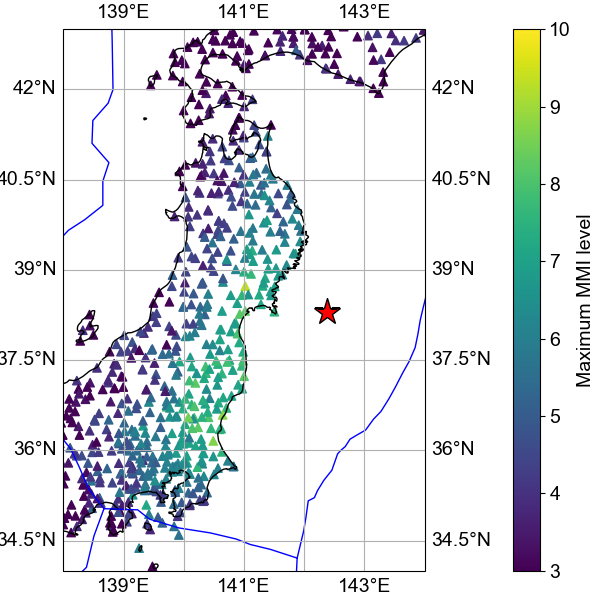

In [74]:
%matplotlib widget

fig = plt.figure(figsize=[6,6],constrained_layout=True)
ax=fig.add_subplot(projection=ccrs.PlateCarree(central_longitude=0))
ax.coastlines()

c = ax.scatter(sta_lons,sta_lats,c=max_mmi,marker='^',vmin=3,vmax=10)
plt.colorbar(c,label='Maximum MMI level')

ax.plot(eq_lon,eq_lat,'r*',markersize=20,markeredgecolor='k')

# Plot tectonic plate boundaries from local file
for feature in plate_boundaries['features']:
    coords = feature['geometry']['coordinates']
    if feature['geometry']['type'] == 'LineString':
        lons, lats = zip(*coords)
        ax.plot(lons, lats, color='blue', linewidth=1, transform=ccrs.PlateCarree())
    elif feature['geometry']['type'] == 'MultiLineString':
        for line in coords:
            lons, lats = zip(*line)
            ax.plot(lons, lats, color='blue', linewidth=1, transform=ccrs.PlateCarree())
ax.set_xlim([138,144])
ax.set_ylim([34,43])
gl = ax.gridlines(draw_labels=True) 

In [75]:
np.max(max_mmi)

9.297027180639954

In [82]:
# Gut check that the MMI levels look ok
downsampled_max_mmi = [np.max(mmi) for mmi in downsampled_mmi_list]

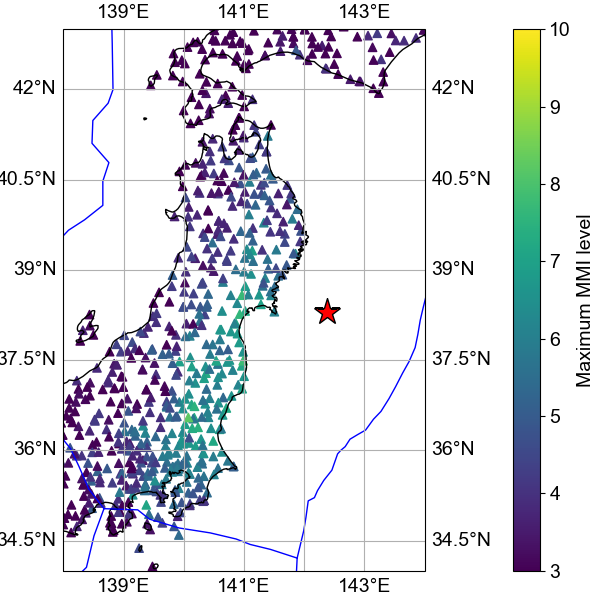

In [83]:
%matplotlib widget

fig = plt.figure(figsize=[6,6],constrained_layout=True)
ax=fig.add_subplot(projection=ccrs.PlateCarree(central_longitude=0))
ax.coastlines()

c = ax.scatter(sta_lons,sta_lats,c=downsampled_max_mmi,marker='^',vmin=3,vmax=10)
plt.colorbar(c,label='Maximum MMI level')

ax.plot(eq_lon,eq_lat,'r*',markersize=20,markeredgecolor='k')

# Plot tectonic plate boundaries from local file
for feature in plate_boundaries['features']:
    coords = feature['geometry']['coordinates']
    if feature['geometry']['type'] == 'LineString':
        lons, lats = zip(*coords)
        ax.plot(lons, lats, color='blue', linewidth=1, transform=ccrs.PlateCarree())
    elif feature['geometry']['type'] == 'MultiLineString':
        for line in coords:
            lons, lats = zip(*line)
            ax.plot(lons, lats, color='blue', linewidth=1, transform=ccrs.PlateCarree())
ax.set_xlim([138,144])
ax.set_ylim([34,43])
gl = ax.gridlines(draw_labels=True) 

Text(0.5, 0, 'Distance from eq (km)')

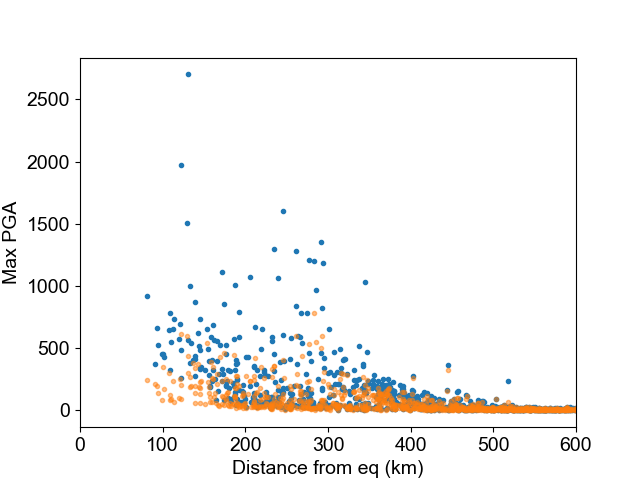

In [89]:
fig,ax = plt.subplots(1)

max_pga = [np.max(pga) for pga in pga_list]
downsampled_max_pga = [np.max(pga) for pga in downsampled_pga_list]

ax.plot(eq_dist_list,max_pga,'.')
ax.plot(eq_dist_list,downsampled_max_pga,'.',alpha=0.5)

ax.set_xlim(0,600)
ax.set_ylabel('Max PGA')
ax.set_xlabel('Distance from eq (km)')

## Save to file

In [102]:
mmi_dict = {'sta_code':unique_stations,'latitude':sta_lats,'longitude':sta_lons,'hypo_dist':eq_dist_list,
            'mmi':mmi_list,'times':times_list,'pga':pga_list,
            'downsampled_mmi':downsampled_mmi_list,'downsampled_times':downsampled_times_list,'downsampled_pga':downsampled_pga_list}

mmi_df = pd.DataFrame(mmi_dict)

In [103]:
# mmi_df.to_pickle('mmi_japan_subduction.pickle')
mmi_df.to_parquet('mmi_japan_subduction.parquet', compression='gzip')